# SkillMatch - Clasificacion de vacantes por habilidades (dataset publico)
**Asignatura:** Mineria de Datos I | **Proyecto de Aula:** SkillMatch
**Pregunta:** que habilidades se asocian con cada categoria de vacante, y se puede predecir la categoria de una vacante a partir de sus habilidades?
**Tipo de tarea:** Clasificacion multiclase (variable objetivo: `category`, 5 clases)
**Dataset:** `all_job_post.csv` (Kaggle, "job-skill-set", derivado de LinkedIn Job Postings). 1.167 vacantes, 5 categorias.
**Limitacion importante:** son vacantes en ingles, de origen LinkedIn y sin columna de ubicacion; no se puede asegurar que representen el mercado de Cartagena. Sirve para validar la idea (habilidades -> categoria) antes de contar con datos locales.

In [1]:
# paso 0: conectar Google Drive (para leer y guardar archivos sin perderlos)
from google.colab import drive
drive.mount('/content/drive')

ruta = '/content/drive/MyDrive/SkillMatch_MineriaDatos/'

Mounted at /content/drive


In [2]:
# paso 1: importar librerias
import os
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# configuracion para que los graficos se vean bien
%matplotlib inline
sns.set_style("whitegrid")

SEMILLA = 42   # misma semilla en todo el notebook para que los resultados se puedan repetir

In [3]:
# paso 2: cargar el dataset
df = pd.read_csv(ruta + 'all_job_post.csv')

# ver las primeras 5 filas
df.head()

,job_id,category,job_title,job_description,job_skill_set
0,3902668440,HR,Sr Human Resource Generalist,SUMMARY\nTHE SR. HR GENERALIST PROVIDES HR EXP...,"['employee relations', 'talent acquisition', '..."
1,3905823748,HR,Human Resources Manager,BE PART OF A STELLAR TEAM AT YSB AS THE MANAGE...,"['Talent Acquisition', 'Employee Performance M..."
2,3905854799,HR,Director of Human Resources,OUR CLIENT IS A THRIVING ORGANIZATION OFFERING...,"['Human Resources Management', 'Recruitment', ..."
3,3905834061,HR,Chief Human Resources Officer,JOB TITLE: CHIEF HUMAN RESOURCES OFFICER (CHRO...,"['talent management', 'organizational developm..."
4,3906250451,HR,Human Resources Generalist (Hybrid Role),DESCRIPTION\n\n WHO WE ARE \n\nAVI-SPL IS A DI...,"['Microsoft Office', 'Data analysis', 'Employe..."


In [4]:
# paso 3: explorar la estructura
print("forma del dataset (filas, columnas):", df.shape)
print("\n--- informacion general ---")
df.info()

forma del dataset (filas, columnas): (1167, 5)

--- informacion general ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1167 entries, 0 to 1166
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   job_id           1167 non-null   int64 
 1   category         1167 non-null   object
 2   job_title        1167 non-null   object
 3   job_description  1167 non-null   object
 4   job_skill_set    1167 non-null   object
dtypes: int64(1), object(4)
memory usage: 45.7+ KB


In [5]:
# paso 4: valores faltantes y duplicados
print("valores faltantes por columna:")
print(df.isnull().sum())
print("\nfilas duplicadas por job_id:", df['job_id'].duplicated().sum())
print("filas completamente duplicadas:", df.duplicated().sum())
# nota: si no hay faltantes no se imputa nada (no se hace solo por demostrar la tecnica)

valores faltantes por columna:
job_id             0
category           0
job_title          0
job_description    0
job_skill_set      0
dtype: int64

filas duplicadas por job_id: 0
filas completamente duplicadas: 0


category
INFORMATION-TECHNOLOGY    240
BUSINESS-DEVELOPMENT      239
FINANCE                   236
SALES                     232
HR                        220
Name: count, dtype: int64

numero de categorias: 5


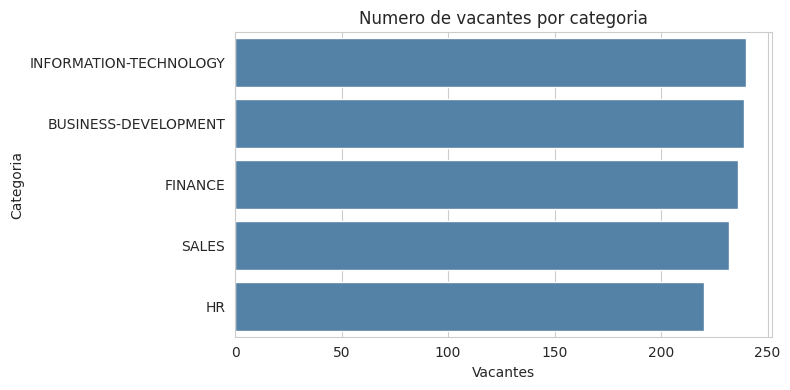

In [6]:
# paso 5: revisar la variable objetivo (categoria de la vacante)
print(df['category'].value_counts())
print("\nnumero de categorias:", df['category'].nunique())

plt.figure(figsize=(8, 4))
sns.countplot(data=df, y='category', order=df['category'].value_counts().index, color='steelblue')
plt.title('Numero de vacantes por categoria')
plt.xlabel('Vacantes')
plt.ylabel('Categoria')
plt.tight_layout()
plt.show()

In [7]:
# paso 6: quedarnos solo con lo que se usa para predecir
# job_id: es solo un identificador
# job_title y job_description: el titulo ('HR Manager') delata la categoria, asi que el modelo
#   se basara SOLO en las habilidades (job_skill_set)
df_modelo = df[['category', 'job_skill_set']].copy()
print("columnas que quedan:", df_modelo.columns.tolist())

columnas que quedan: ['category', 'job_skill_set']


In [8]:
# paso 7: convertir job_skill_set de texto a lista de verdad
# en el CSV cada fila es un texto con forma de lista: "['a', 'b']"
def texto_a_lista(texto):
    try:
        lista = ast.literal_eval(texto)
        # minusculas y sin espacios sobrantes: 'Communication' y 'communication' son la misma habilidad
        return sorted(set(h.strip().lower() for h in lista if isinstance(h, str) and h.strip()))
    except (ValueError, SyntaxError):
        return []

df_modelo['habilidades'] = df_modelo['job_skill_set'].apply(texto_a_lista)
df_modelo['n_habilidades'] = df_modelo['habilidades'].apply(len)

print("vacantes sin habilidades legibles:", (df_modelo['n_habilidades'] == 0).sum())
print("\nhabilidades por vacante:")
print(df_modelo['n_habilidades'].describe())
df_modelo[['category', 'habilidades']].head()

vacantes sin habilidades legibles: 0

habilidades por vacante:
count    1167.000000
mean       17.851757
std         4.980524
min         5.000000
25%        15.000000
50%        18.000000
75%        20.000000
max        43.000000
Name: n_habilidades, dtype: float64


,category,habilidades
0,HR,"[ada, analytical skills, change management, co..."
1,HR,"[adaptability, attention to detail, background..."
2,HR,"[adaptability, attention to detail, collaborat..."
3,HR,"[change management, collaboration, communicati..."
4,HR,"[attention to detail, change management, commu..."


habilidades distintas: 4984


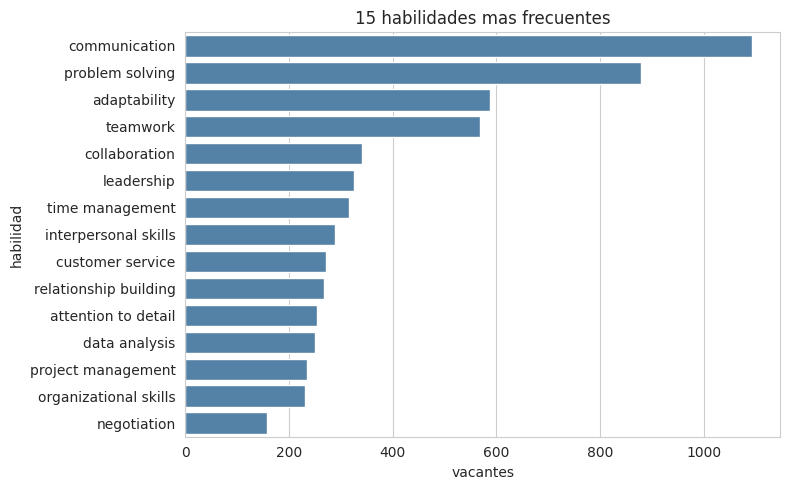

In [9]:
# paso 8: habilidades mas frecuentes en todo el dataset (solo para explorar)
contador_total = Counter(h for lista in df_modelo['habilidades'] for h in lista)
print("habilidades distintas:", len(contador_total))

top = pd.DataFrame(contador_total.most_common(15), columns=['habilidad', 'vacantes'])
plt.figure(figsize=(8, 5))
sns.barplot(data=top, y='habilidad', x='vacantes', color='steelblue')
plt.title('15 habilidades mas frecuentes')
plt.tight_layout()
plt.show()

In [10]:
# paso 9: dividir en entrenamiento (80%) y prueba (20%) ANTES de construir las variables
# stratify mantiene la misma proporcion de categorias en ambos conjuntos
# (asi las habilidades que se usan se eligen mirando solo el entrenamiento)
train, test = train_test_split(df_modelo, test_size=0.2, random_state=SEMILLA,
                               stratify=df_modelo['category'])
print("Datos de entrenamiento:", train.shape)
print("Datos de prueba:", test.shape)

Datos de entrenamiento: (933, 4)
Datos de prueba: (234, 4)


In [11]:
# paso 10: convertir las habilidades a columnas numericas (0/1)
# solo se usan habilidades que aparecen en al menos MIN_VACANTES vacantes DEL ENTRENAMIENTO
# (las muy raras no ayudan a predecir)
MIN_VACANTES = 10

def construir_variables(train, test, min_vacantes):
    cont = Counter(h for lista in train['habilidades'] for h in lista)
    validas = {h for h, c in cont.items() if c >= min_vacantes}
    filtrar = lambda lista: [h for h in lista if h in validas]
    mlb = MultiLabelBinarizer()
    X_tr = pd.DataFrame(mlb.fit_transform(train['habilidades'].apply(filtrar)),
                        columns=mlb.classes_, index=train.index)
    X_te = pd.DataFrame(mlb.transform(test['habilidades'].apply(filtrar)),
                        columns=mlb.classes_, index=test.index)
    return X_tr, X_te

X_train, X_test = construir_variables(train, test, MIN_VACANTES)
y_train, y_test = train['category'], test['category']

print("habilidades usadas como variables:", X_train.shape[1])
print("forma de X_train:", X_train.shape, "| forma de X_test:", X_test.shape)
# las variables son 0/1, por eso no hace falta escalar

habilidades usadas como variables: 198
forma de X_train: (933, 198) | forma de X_test: (234, 198)


In [12]:
# paso 11: modelo de referencia (el mas simple posible)
# siempre responde la categoria mas frecuente; sirve para saber si el modelo realmente aprende
base = DummyClassifier(strategy='most_frequent')
base.fit(X_train, y_train)
acc_base = accuracy_score(y_test, base.predict(X_test))
print(f"Accuracy del modelo de referencia: {acc_base:.4f}")

Accuracy del modelo de referencia: 0.2051


In [13]:
# paso 12: crear y entrenar el modelo principal (regresion logistica)
modelo = LogisticRegression(max_iter=1000, random_state=SEMILLA)
modelo.fit(X_train, y_train)
print("Modelo entrenado")
print("Categorias que conoce:", modelo.classes_.tolist())

Modelo entrenado
Categorias que conoce: ['BUSINESS-DEVELOPMENT', 'FINANCE', 'HR', 'INFORMATION-TECHNOLOGY', 'SALES']


In [14]:
# paso 13: predecir sobre los datos de prueba y calcular metricas
y_pred = modelo.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1m = f1_score(y_test, y_pred, average='macro')

print("=== Metricas de Clasificacion (conjunto de prueba) ===")
print(f"Accuracy modelo:      {acc:.4f}")
print(f"Accuracy referencia:  {acc_base:.4f}")
print(f"F1 macro:             {f1m:.4f}")
print("\n--- reporte por categoria ---")
print(classification_report(y_test, y_pred))

=== Metricas de Clasificacion (conjunto de prueba) ===
Accuracy modelo:      0.7308
Accuracy referencia:  0.2051
F1 macro:             0.7346

--- reporte por categoria ---
                        precision    recall  f1-score   support

  BUSINESS-DEVELOPMENT       0.55      0.56      0.56        48
               FINANCE       0.93      0.79      0.85        47
                    HR       0.92      0.80      0.85        44
INFORMATION-TECHNOLOGY       0.75      0.92      0.82        48
                 SALES       0.58      0.60      0.59        47

              accuracy                           0.73       234
             macro avg       0.75      0.73      0.73       234
          weighted avg       0.74      0.73      0.73       234



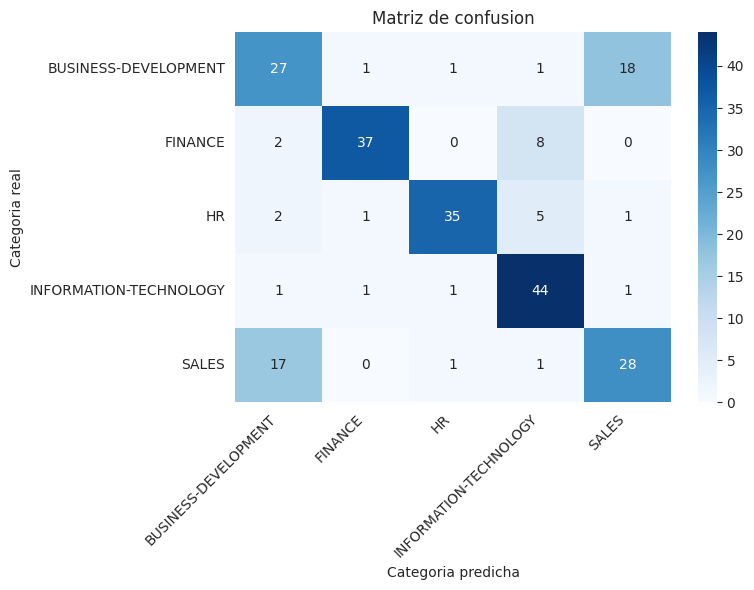

In [15]:
# paso 14: matriz de confusion
etiquetas = modelo.classes_
cm = confusion_matrix(y_test, y_pred, labels=etiquetas)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=etiquetas, yticklabels=etiquetas)
plt.xlabel('Categoria predicha')
plt.ylabel('Categoria real')
plt.title('Matriz de confusion')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [16]:
# paso 15: en que se equivoca mas el modelo (pares de categorias mas confundidas)
errores = pd.DataFrame({'real': y_test.values, 'predicha': y_pred})
errores = errores[errores['real'] != errores['predicha']]
pares = errores.value_counts().reset_index(name='casos').head(6)
print("errores totales:", len(errores), "de", len(y_test))
print(pares.to_string(index=False))

errores totales: 63 de 234
                real               predicha  casos
BUSINESS-DEVELOPMENT                  SALES     18
               SALES   BUSINESS-DEVELOPMENT     17
             FINANCE INFORMATION-TECHNOLOGY      8
                  HR INFORMATION-TECHNOLOGY      5
                  HR   BUSINESS-DEVELOPMENT      2
             FINANCE   BUSINESS-DEVELOPMENT      2


In [17]:
# paso 16: validacion cruzada (5 pliegues) en el entrenamiento, comparando 3 modelos
# con una sola division de 234 vacantes de prueba el resultado puede variar por suerte;
# la validacion cruzada da un promedio mas confiable
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
candidatos = {
    'Regresion logistica': LogisticRegression(max_iter=1000, random_state=SEMILLA),
    'Naive Bayes (Bernoulli)': BernoulliNB(),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=SEMILLA, n_jobs=-1),
}

filas = []
for nombre, m in candidatos.items():
    puntajes = cross_val_score(m, X_train, y_train, cv=cv, scoring='accuracy')
    m.fit(X_train, y_train)
    filas.append({
        'modelo': nombre,
        'accuracy_cv_media': round(puntajes.mean(), 4),
        'accuracy_cv_desv': round(puntajes.std(), 4),
        'accuracy_prueba': round(accuracy_score(y_test, m.predict(X_test)), 4),
    })
comparacion = pd.DataFrame(filas)
print(comparacion.to_string(index=False))
# nota: se mantiene la regresion logistica como modelo principal por ser simple e interpretable
# (sus coeficientes dicen que habilidades empujan hacia cada categoria)

                 modelo  accuracy_cv_media  accuracy_cv_desv  accuracy_prueba
    Regresion logistica             0.7728            0.0271           0.7308
Naive Bayes (Bernoulli)             0.7792            0.0187           0.7650
          Random Forest             0.7888            0.0256           0.7778


In [18]:
# paso 17: sensibilidad al umbral de habilidades (MIN_VACANTES), con validacion cruzada
# sirve para justificar por que se eligio 10 y no otro valor
filas = []
for umbral in [5, 10, 20, 40]:
    Xa, _ = construir_variables(train, test, umbral)
    p = cross_val_score(LogisticRegression(max_iter=1000, random_state=SEMILLA),
                        Xa, y_train, cv=cv, scoring='accuracy')
    filas.append({'min_vacantes': umbral, 'habilidades_usadas': Xa.shape[1],
                  'accuracy_cv_media': round(p.mean(), 4)})
sens = pd.DataFrame(filas)
print(sens.to_string(index=False))

 min_vacantes  habilidades_usadas  accuracy_cv_media
            5                 395             0.7793
           10                 198             0.7728
           20                 109             0.7546
           40                  63             0.7171


In [19]:
# paso 18: que habilidades empujan hacia cada categoria
# coeficiente positivo alto = esa habilidad hace mas probable la categoria
coef = pd.DataFrame(modelo.coef_, index=modelo.classes_, columns=X_train.columns)

for categoria in coef.index:
    print(f"\n{categoria}")
    print(coef.loc[categoria].sort_values(ascending=False).head(8).round(2).to_string())


BUSINESS-DEVELOPMENT
business development     2.29
market research          1.24
lead generation          1.23
cold calling             1.04
networking               1.01
salesforce               0.87
relationship building    0.86
sales                    0.86

FINANCE
financial reporting    2.13
finance                1.71
financial analysis     1.58
financial modeling     1.39
accounting             1.37
variance analysis      1.30
workday                1.00
accounts receivable    0.98

HR
hris                          1.69
employee relations            1.65
confidentiality               1.57
human resources               1.24
onboarding                    1.18
performance management        1.12
human resources management    1.09
recruiting                    1.08

INFORMATION-TECHNOLOGY
troubleshooting           1.93
information technology    1.36
active directory          1.31
network administration    1.10
jira                      1.02
sharepoint                0.99
technical s

In [20]:
# paso 19: guardar resultados y datos preparados en Drive (para el repositorio, el informe y MinedApp)
carpeta_res = ruta + 'resultados/'
os.makedirs(carpeta_res, exist_ok=True)

resumen = pd.DataFrame({
    'metrica': ['filas_totales', 'habilidades_usadas', 'filas_entrenamiento', 'filas_prueba',
                'accuracy_referencia', 'accuracy_modelo', 'f1_macro'],
    'valor': [len(df), X_train.shape[1], len(X_train), len(X_test),
              round(acc_base, 4), round(acc, 4), round(f1m, 4)]
})
resumen.to_csv(carpeta_res + 'clasificacion_vacantes_metricas.csv', index=False)
comparacion.to_csv(carpeta_res + 'clasificacion_vacantes_comparacion_modelos.csv', index=False)
sens.to_csv(carpeta_res + 'clasificacion_vacantes_sensibilidad_umbral.csv', index=False)

top_por_categoria = pd.concat(
    [coef.loc[c].sort_values(ascending=False).head(8).rename_axis('habilidad').reset_index()
        .assign(categoria=c) for c in coef.index]
)
top_por_categoria.to_csv(carpeta_res + 'clasificacion_vacantes_habilidades_por_categoria.csv', index=False)

# dataset preparado completo (entrenamiento + prueba) con las variables 0/1, para MinedApp
preparado = pd.concat([X_train.assign(category=y_train), X_test.assign(category=y_test)])
preparado = preparado[['category'] + list(X_train.columns)]
preparado.to_csv(carpeta_res + 'dataset_vacantes_preparado.csv', index=False)

# version compacta (las 30 habilidades mas frecuentes) para explorar mas comodo en MinedApp
top30 = list(X_train.sum().sort_values(ascending=False).head(30).index)
preparado[['category'] + top30].to_csv(carpeta_res + 'dataset_vacantes_minedapp_top30.csv', index=False)

print(resumen)
print("\nArchivos guardados en:", carpeta_res)
print(os.listdir(carpeta_res))

               metrica      valor
0        filas_totales  1167.0000
1   habilidades_usadas   198.0000
2  filas_entrenamiento   933.0000
3         filas_prueba   234.0000
4  accuracy_referencia     0.2051
5      accuracy_modelo     0.7308
6             f1_macro     0.7346

Archivos guardados en: /content/drive/MyDrive/SkillMatch_MineriaDatos/resultados/
['clasificacion_vacantes_metricas.csv', 'clasificacion_vacantes_comparacion_modelos.csv', 'clasificacion_vacantes_sensibilidad_umbral.csv', 'clasificacion_vacantes_habilidades_por_categoria.csv', 'dataset_vacantes_preparado.csv', 'dataset_vacantes_minedapp_top30.csv']
